# №13 зертханалық жұмыс
## Жіктеу және деректерді талдау міндеттерін шешу үшін алдын ала оқытылған модельдер мен тасымалды оқытуды қолдану.

Кіріктірілген Digits жиынын және ресми `models/squeezenet1_1-b8a52dc0.pth` файлын пайдаланамыз. Оны жинақ түбіріндегі `models` ішіне орналастырыңыз. Басқа жерде болса, ядро ортасында `LAB13_WEIGHTS_PATH` беріңіз. SHA-256 жүктеуге дейін тексеріледі. Өлшеулер мен екі сурет `lab13_artifacts` ішінде сақталады.

[SqueezeNet1_1 және ресми бақылау нүктесінің параметрлері](https://docs.pytorch.org/vision/stable/models/generated/torchvision.models.squeezenet1_1.html).


### Орта, салмақтар және бекітілген баптаулар

Салыстыруды CPU-да PyTorch-тың бір ағынымен орындаймыз. Үш режим де бір кіріс өлшемін, бірдей деректерді, бастапқы бас модульді және топтамалар ретін пайдаланады.


In [1]:
import argparse
from copy import deepcopy
from hashlib import sha256
from importlib.metadata import version
import json
import os
from pathlib import Path
import platform

import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
import numpy as np
from sklearn.datasets import load_digits
from sklearn.metrics import accuracy_score, confusion_matrix, f1_score
from sklearn.model_selection import train_test_split
import torch
from torch import nn
from torch.nn import functional as F
from torchvision.models import SqueezeNet1_1_Weights, squeezenet1_1

ROOT = Path.cwd() / "lab13_artifacts"
FIGURES = ROOT / "figures"
WEIGHTS_NAME = "squeezenet1_1-b8a52dc0.pth"
explicit_weights = os.getenv("LAB13_WEIGHTS_PATH")
weight_candidates = (Path.cwd() / "models" / WEIGHTS_NAME,
                     Path.cwd().parent / "models" / WEIGHTS_NAME)
WEIGHTS_PATH = (Path(explicit_weights) if explicit_weights else
                next((path for path in weight_candidates if path.is_file()), weight_candidates[0]))
WEIGHTS_SHA256 = "b8a52dc049b60e4b6ab68ad0df457362afab8b6304b2febdc1650a5dab4d7e7b"
PACKAGES = ("numpy", "scikit-learn", "matplotlib", "torch", "torchvision")
THREAD_ENVIRONMENT = ("OMP_NUM_THREADS", "OPENBLAS_NUM_THREADS", "MKL_NUM_THREADS",
                      "BLIS_NUM_THREADS", "NUMEXPR_NUM_THREADS")
MODES = ("A", "B", "C")
MODE_LABELS = {"A": "A · кездейсоқ, қатырылған", "B": "B · ImageNet, қатырылған", "C": "C · ImageNet, соңғы Fire"}
COLORS = {"A": "#666666", "B": "#176B87", "C": "#B34B20"}
INPUT_SIZE = 64
LAST_FIRE = 12
BATCH_SIZE = 64
EPOCHS = 8
HEAD_LR, FIRE_LR, WEIGHT_DECAY = .003, .0003, .01
MEAN, STD = (.485, .456, .406), (.229, .224, .225)
LABELS = list(range(10))
plt.rcParams["font.family"] = "DejaVu Sans"


def configure_runtime():
    torch.set_num_threads(1)
    torch.use_deterministic_algorithms(True)


from IPython.display import Image, display

configure_runtime()
FIGURES.mkdir(parents=True, exist_ok=True)
for package in PACKAGES:
    print(package, version(package))
print("Жергілікті салмақтар", WEIGHTS_PATH)


numpy 2.5.4


scikit-learn 1.9.1
matplotlib 3.11.2
torch 2.9.1+cpu
torchvision 0.24.1+cpu
Жергілікті салмақтар models/squeezenet1_1-b8a52dc0.pth


### 1, 3 және 4-қадамдар. Деректер, бөлінім және кіріс

Бастапқы 1797 бейнеден 1050 таңдап, стратификациямен 600 train, 200 validation және 250 test құрамыз. Бастапқы идентификаторларды сақтаймыз. Digits үшін 64 × 64 оқу өлшемі мен ImageNet арналық нормалауын пайдаланамыз.


In [2]:
def load_split():
    digits = load_digits()
    y = digits.target
    ids = np.arange(len(y))
    chosen, unused = train_test_split(ids, train_size=1050, stratify=y, random_state=2026)
    development, test = train_test_split(chosen, test_size=250, stratify=y[chosen], random_state=2027)
    train, validation = train_test_split(development, test_size=200, stratify=y[development], random_state=2028)
    splits = {"train": train, "validation": validation, "test": test, "unused": unused}
    counts = {name: np.bincount(y[rows], minlength=10).tolist() for name, rows in splits.items()}
    print("Бөліктер өлшемдері", {name: len(rows) for name, rows in splits.items()})
    print("0–9 кластарының саны", counts)
    return {"images": digits.images, "y": y, "splits": splits, "class_counts": counts}


def preprocess(images):
    gray = torch.as_tensor(images, dtype=torch.float32)[:, None] / 16
    resized = F.interpolate(gray, size=(INPUT_SIZE, INPUT_SIZE), mode="bilinear", align_corners=False)
    rgb = resized.repeat(1, 3, 1, 1)
    mean = torch.tensor(MEAN, dtype=rgb.dtype)[None, :, None, None]
    std = torch.tensor(STD, dtype=rgb.dtype)[None, :, None, None]
    return (rgb - mean) / std


data = load_split()
example = preprocess(data["images"][data["splits"]["train"][:4]])
assert example.shape == (4, 3, 64, 64)
print("NCHW тензоры", tuple(example.shape), example.dtype)


Бөліктер өлшемдері {'train': 600, 'validation': 200, 'test': 250, 'unused': 747}
0–9 кластарының саны {'train': [59, 61, 58, 61, 61, 61, 61, 60, 58, 60], 'validation': [20, 20, 20, 20, 20, 20, 20, 20, 20, 20], 'test': [25, 25, 25, 26, 25, 25, 25, 25, 24, 25], 'unused': [74, 76, 74, 76, 75, 76, 75, 74, 72, 75]}
NCHW тензоры (4, 3, 64, 64) torch.float32


### 2 және 5-қадамдар. Салмақтарды жүктеу және кэш

SHA-256 тексеріп, салмақтарды `weights_only=True` арқылы жүктейміз және екі негізді де қатырамыз. A мен B үшін векторларды, C үшін бекітілген төменгі бөліктен кейінгі карталарды кэштейміз. Дәуірлер таңдалғанға дейін кэште тек train мен validation қолданылады.


In [3]:
def state_digest(module):
    digest = sha256()
    for name, tensor in sorted(module.state_dict().items()):
        digest.update(name.encode("utf-8"))
        digest.update(str(tensor.dtype).encode("ascii"))
        digest.update(str(tuple(tensor.shape)).encode("ascii"))
        digest.update(tensor.detach().cpu().contiguous().numpy().tobytes())
    return digest.hexdigest()


def load_backbones(weights_path=WEIGHTS_PATH):
    weights_path = Path(weights_path)
    if not weights_path.is_file():
        raise FileNotFoundError(f"Ресми бақылау нүктесін {weights_path} жолына орналастырыңыз немесе --weights беріңіз")
    actual_sha = sha256(weights_path.read_bytes()).hexdigest()
    if actual_sha != WEIGHTS_SHA256:
        raise ValueError(f"Күтпеген бақылау нүктесінің SHA-256 мәні: {actual_sha}")
    with torch.random.fork_rng(devices=[]):
        torch.manual_seed(2029)
        random_model = squeezenet1_1(weights=None)
        pretrained_model = squeezenet1_1(weights=None)
        pretrained_model.load_state_dict(torch.load(weights_path, map_location="cpu", weights_only=True), strict=True)
        torch.manual_seed(2030)
        initial_head = nn.Linear(512, 10)
    random_features = random_model.features.requires_grad_(False).eval()
    pretrained_features = pretrained_model.features.requires_grad_(False).eval()
    if len(pretrained_features) != LAST_FIRE + 1 or type(pretrained_features[LAST_FIRE]).__name__ != "Fire":
        raise ValueError("SqueezeNet1_1 белгілер құрылымы күтілгенге сәйкес емес")
    models = {"random": random_features, "pretrained": pretrained_features,
              "prefix": pretrained_features[:LAST_FIRE].eval(), "initial_head": initial_head}
    info = {"file": weights_path.name, "bytes": weights_path.stat().st_size, "sha256": actual_sha,
            "variant": "SqueezeNet1_1_Weights.IMAGENET1K_V1",
            "url": SqueezeNet1_1_Weights.IMAGENET1K_V1.url,
            "last_fire_index": LAST_FIRE, "strict_weights_only_load": True,
            "backbone_parameters": sum(p.numel() for p in pretrained_features.parameters()),
            "last_fire_parameters": sum(p.numel() for p in pretrained_features[LAST_FIRE].parameters()),
            "head_parameters": sum(p.numel() for p in initial_head.parameters())}
    print("Салмақтар мен параметрлер", info)
    return models, info


def frozen_fingerprints(backbones):
    return {name: state_digest(backbones[name]) for name in ("random", "pretrained", "prefix", "initial_head")}


def pool_maps(maps):
    return F.adaptive_avg_pool2d(maps, (1, 1)).flatten(1)


def cache_inputs(backbones, images):
    random_embeddings, pretrained_embeddings, prefix_maps = [], [], []
    # Қалыпты no_grad тензорларын кейін оқытылатын қабаттардың кірісі ретінде қолдануға болады.
    with torch.no_grad():
        for start in range(0, len(images), BATCH_SIZE):
            x = preprocess(images[start:start + BATCH_SIZE])
            random_embeddings.append(pool_maps(backbones["random"](x)))
            prefix = backbones["prefix"](x)
            pretrained_embeddings.append(pool_maps(backbones["pretrained"][LAST_FIRE](prefix)))
            prefix_maps.append(prefix)
    return {mode: torch.cat(batches) for mode, batches in zip(MODES, (random_embeddings, pretrained_embeddings, prefix_maps))}


def training_cache(data, backbones):
    train, validation = (data["splits"][name] for name in ("train", "validation"))
    ordered = np.concatenate((train, validation))
    cache = cache_inputs(backbones, data["images"][ordered])
    n_train = len(train)
    return {mode: (x[:n_train], x[n_train:]) for mode, x in cache.items()}


backbones, weight_info = load_backbones()
before = frozen_fingerprints(backbones)
cache = training_cache(data, backbones)
print("Train және validation пішіндері", {mode: [list(a.shape), list(b.shape)]
      for mode, (a, b) in cache.items()})


Салмақтар мен параметрлер {'file': 'squeezenet1_1-b8a52dc0.pth', 'bytes': 4958839, 'sha256': 'b8a52dc049b60e4b6ab68ad0df457362afab8b6304b2febdc1650a5dab4d7e7b', 'variant': 'SqueezeNet1_1_Weights.IMAGENET1K_V1', 'url': 'https://download.pytorch.org/models/squeezenet1_1-b8a52dc0.pth', 'last_fire_index': 12, 'strict_weights_only_load': True, 'backbone_parameters': 722496, 'last_fire_parameters': 197184, 'head_parameters': 5130}


Train және validation пішіндері {'A': [[600, 512], [200, 512]], 'B': [[600, 512], [200, 512]], 'C': [[600, 512, 3, 3], [200, 512, 3, 3]]}


### 6-қадам. Қатырылған белгілер үстіндегі екі бас модуль

A және B режимдері белгілерді бөліп алудың бастапқы салмақтарымен ерекшеленеді. Әрқайсысы үшін сегіз дәуір орындаймыз. Validation macro-F1 алғашқы максимумын таңдап, осы күйді қалпына келтіреміз.


In [4]:
def new_mode(mode, backbones):
    head = deepcopy(backbones["initial_head"])
    groups = [{"params": head.parameters(), "lr": HEAD_LR}]
    if mode == "C":
        fire = deepcopy(backbones["pretrained"][LAST_FIRE]).requires_grad_(True)
        model = nn.Sequential(fire, nn.AdaptiveAvgPool2d(1), nn.Flatten(), head)
        groups.append({"params": fire.parameters(), "lr": FIRE_LR})
    else:
        model = head
    return model, torch.optim.AdamW(groups, weight_decay=WEIGHT_DECAY)


def predict_labels(model, inputs):
    model.eval()
    with torch.no_grad():
        return torch.cat([model(batch).argmax(dim=1) for batch in inputs.split(BATCH_SIZE)]).numpy()


def train_mode(mode, data, backbones, cache):
    model, optimizer = new_mode(mode, backbones)
    train, validation = (data["splits"][name] for name in ("train", "validation"))
    train_y = torch.as_tensor(data["y"][train], dtype=torch.long)
    val_y = data["y"][validation]
    train_x, val_x = cache[mode]
    order_generator = torch.Generator().manual_seed(2031)
    training_log = []
    best_score, best_state = -1.0, None
    trainable_count = sum(p.numel() for p in model.parameters() if p.requires_grad)
    initial_hash = state_digest(model)
    head_initial_hash = state_digest(model[-1] if mode == "C" else model)
    fire_initial_hash = state_digest(model[0]) if mode == "C" else None
    steps = 0
    for epoch in range(1, EPOCHS + 1):
        model.train()
        total_loss = 0.0
        order = torch.randperm(len(train_y), generator=order_generator)
        for batch in order.split(BATCH_SIZE):
            optimizer.zero_grad(set_to_none=True)
            logits = model(train_x[batch])
            loss = F.cross_entropy(logits, train_y[batch])
            loss.backward()
            optimizer.step()
            steps += 1
            total_loss += loss.item() * len(batch)
        predictions = predict_labels(model, val_x)
        score = float(f1_score(val_y, predictions, labels=LABELS, average="macro", zero_division=0))
        training_log.append({"epoch": epoch, "train_CE": total_loss / len(train_y), "validation_macro_F1": score,
                             "validation_accuracy": float(accuracy_score(val_y, predictions)), "optimizer_steps": steps})
        if score > best_score:
            best_score = score
            best_epoch = epoch
            best_state = deepcopy(model.state_dict())
    model.load_state_dict(best_state, strict=True)
    model.eval()
    fire_selected_hash = state_digest(model[0]) if mode == "C" else None
    if mode == "C":
        assert fire_initial_hash != fire_selected_hash
    row = {"mode": mode, "trainable_parameters": trainable_count, "optimizer_steps": steps,
           "selected_epoch": best_epoch, "selected_optimizer_steps": training_log[best_epoch - 1]["optimizer_steps"],
           "selected_validation_macro_F1": best_score, "log": training_log,
           "train_input_shape": list(train_x.shape), "validation_input_shape": list(val_x.shape),
           "initial_model_sha256": initial_hash, "selected_model_sha256": state_digest(model),
           "common_initial_head_sha256": head_initial_hash,
           "initial_fire_sha256": fire_initial_hash, "selected_fire_sha256": fire_selected_hash}
    print(mode, "оқытылатын", trainable_count, "қадамдар", steps, "таңдалған дәуір", best_epoch,
          f"валидациядағы macro-F1 {best_score:.6f}")
    return model, row


fitted = {mode: train_mode(mode, data, backbones, cache) for mode in ("A", "B")}


A оқытылатын 5130 қадамдар 80 таңдалған дәуір 7 валидациядағы macro-F1 0.292338


B оқытылатын 5130 қадамдар 80 таңдалған дәуір 6 валидациядағы macro-F1 0.910238


### 7–8-қадамдар. Соңғы Fire және дәуір таңдау

Тек соңғы Fire мен C бас модулі оқытылады, жылдамдықтары 0,0003 және 0,003 мәндеріне тең. Айқас энтропия дәуір нысандары бойынша қосылады. Validation графигіндегі шеңберленген нүктелер таңдалған күйлерді білдіреді.


C оқытылатын 202314 қадамдар 80 таңдалған дәуір 8 валидациядағы macro-F1 0.950110


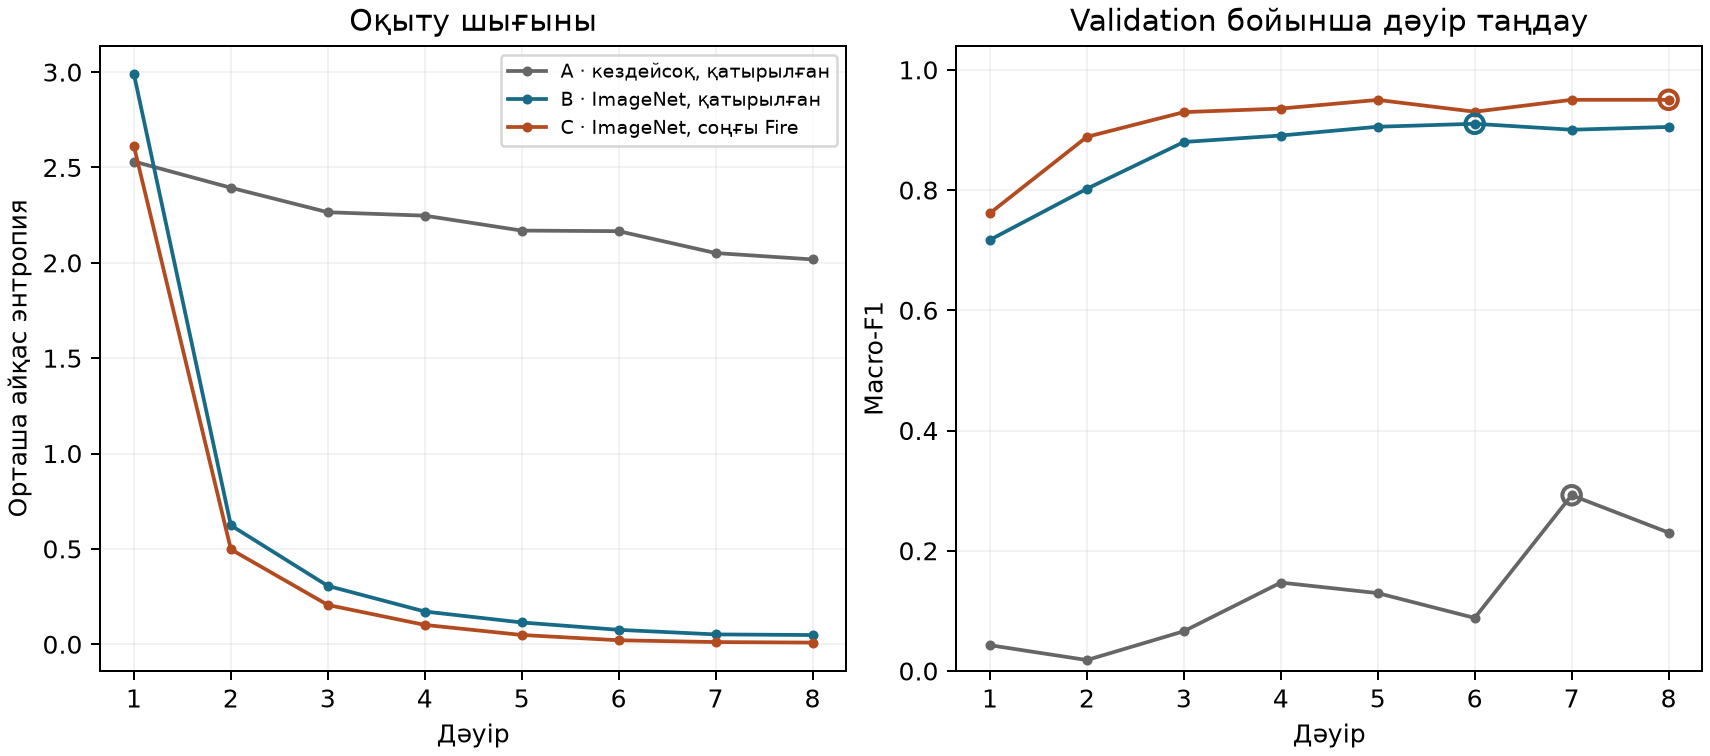

In [5]:
def plot_validation(fitted, path):
    fig, axes = plt.subplots(1, 2, figsize=(9.5, 4.2), layout="constrained")
    for mode in MODES:
        row = fitted[mode][1]
        epochs = [record["epoch"] for record in row["log"]]
        axes[0].plot(epochs, [record["train_CE"] for record in row["log"]], marker="o", markersize=3,
                     color=COLORS[mode], label=MODE_LABELS[mode])
        axes[1].plot(epochs, [record["validation_macro_F1"] for record in row["log"]], marker="o", markersize=3,
                     color=COLORS[mode])
        axes[1].scatter(row["selected_epoch"], row["selected_validation_macro_F1"], s=55,
                        facecolors="none", edgecolors=COLORS[mode], linewidths=1.6, zorder=4)
    axes[0].set(title="Оқыту шығыны", ylabel="Орташа айқас энтропия")
    axes[1].set(title="Validation бойынша дәуір таңдау", ylabel="Macro-F1", ylim=(0, 1.04))
    axes[0].legend(fontsize=7.5, loc="best")
    for axis in axes:
        axis.set(xlabel="Дәуір", xticks=range(1, EPOCHS + 1))
        axis.grid(alpha=.16)
    fig.savefig(path, dpi=180)
    plt.close(fig)


fitted["C"] = train_mode("C", data, backbones, cache)
after = frozen_fingerprints(backbones)
assert before == after
plot_validation(fitted, FIGURES / "ch13_05_transfer_validation.png")
display(Image(filename=str(FIGURES / "ch13_05_transfer_validation.png")))


### 9-қадам. Test жиынындағы таңдалған үш күй

Үш дәуір де таңдалғаннан кейін бірдей тест жиынын бағалаймыз. C режимінің шатасу матрицасы шын цифрлар жолдары және болжанған цифрлар бағандары бойынша оқылады.


A test дұрыс жіктеу үлесі 0.400000, macro-F1 0.297938
B test дұрыс жіктеу үлесі 0.924000, macro-F1 0.922597
C test дұрыс жіктеу үлесі 0.936000, macro-F1 0.935474


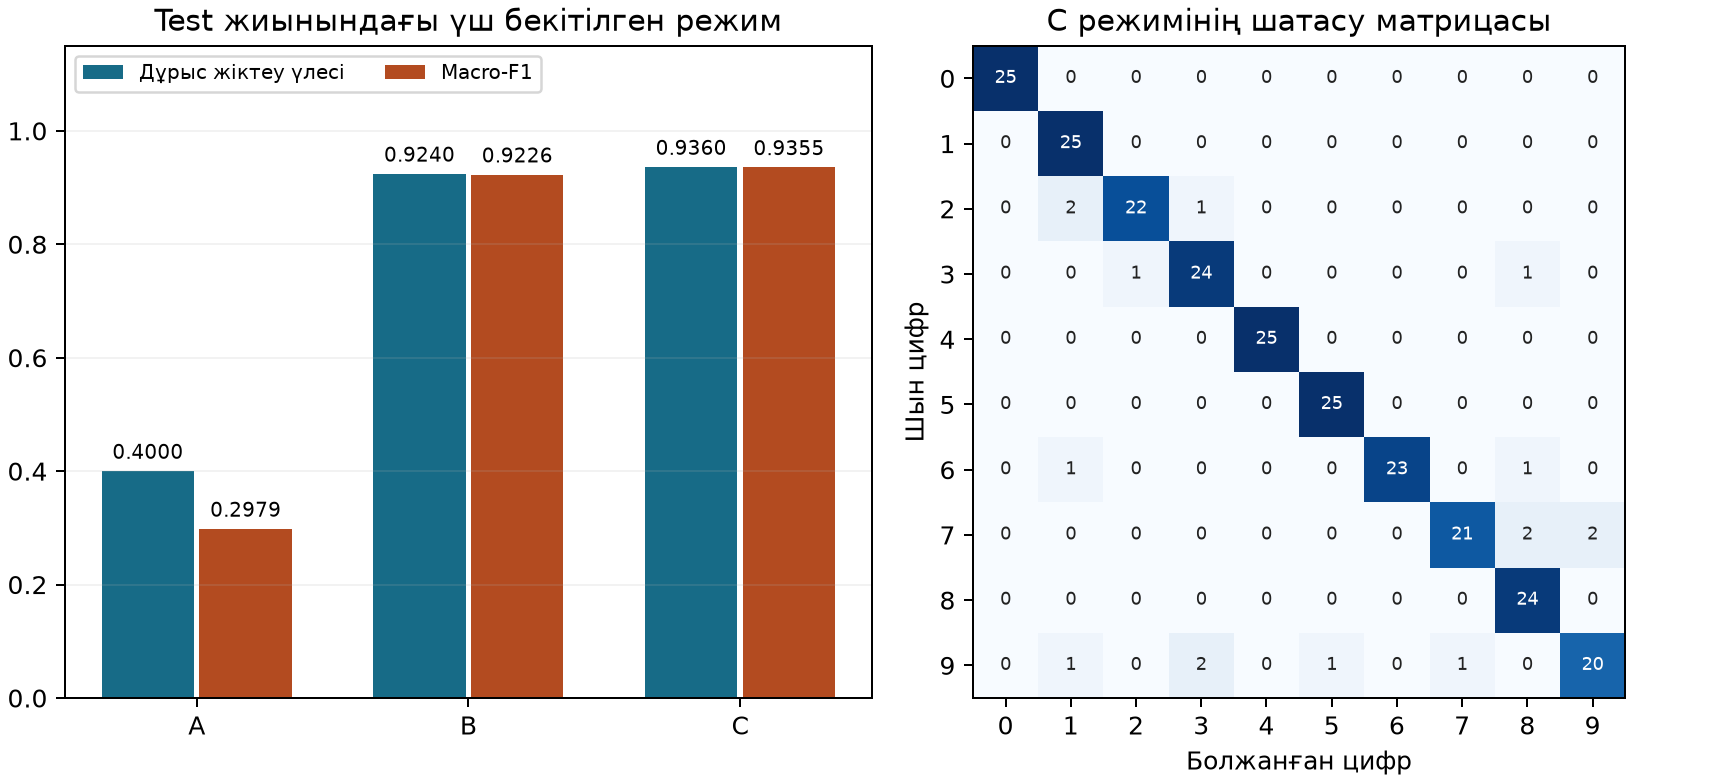

In [6]:
def test_selected(data, backbones, fitted):
    if set(fitted) != set(MODES):
        raise ValueError("Test басталғанға дейін validation бойынша үш күйдің бәрін таңдаңыз")
    test = data["splits"]["test"]
    features = cache_inputs(backbones, data["images"][test])
    y = data["y"][test]
    rows, predictions = [], {}
    for mode in MODES:
        model, selection = fitted[mode]
        assert selection["selected_model_sha256"] == state_digest(model)
        pred = predict_labels(model, features[mode])
        predictions[mode] = pred.tolist()
        row = {"mode": mode, "accuracy": float(accuracy_score(y, pred)),
               "macro_F1": float(f1_score(y, pred, labels=LABELS, average="macro", zero_division=0)),
               "confusion_0_to_9": confusion_matrix(y, pred, labels=LABELS).tolist()}
        rows.append(row)
        print(mode, f"test дұрыс жіктеу үлесі {row['accuracy']:.6f}, macro-F1 {row['macro_F1']:.6f}")
    return {"rows": rows, "test_row_ids": test.tolist(), "test_labels": y.tolist(),
            "predictions": predictions, "test_models_refit": False, "test_used_for_selection": False}


def plot_test(evaluation, path):
    fig, axes = plt.subplots(1, 2, figsize=(9.5, 4.35), layout="constrained")
    positions = np.arange(3)
    for offset, key, label, color in ((-.18, "accuracy", "Дұрыс жіктеу үлесі", "#176B87"),
                                       (.18, "macro_F1", "Macro-F1", "#B34B20")):
        bars = axes[0].bar(positions + offset, [row[key] for row in evaluation["rows"]],
                           width=.34, label=label, color=color)
        axes[0].bar_label(bars, fmt="%.4f", padding=3, fontsize=8)
    axes[0].set(title="Test жиынындағы үш бекітілген режим", xticks=positions, xticklabels=MODES, ylim=(0, 1.15))
    axes[0].legend(ncols=2, loc="upper left", fontsize=8)
    axes[0].grid(axis="y", alpha=.16)
    matrix = np.array(evaluation["rows"][2]["confusion_0_to_9"])
    axes[1].imshow(matrix, cmap="Blues", vmin=0)
    axes[1].set(title="C режимінің шатасу матрицасы", xlabel="Болжанған цифр", ylabel="Шын цифр",
                xticks=LABELS, yticks=LABELS)
    for row, column in np.ndindex(matrix.shape):
        value = matrix[row, column]
        axes[1].text(column, row, str(value), ha="center", va="center", fontsize=7,
                     color="white" if value > matrix.max() / 2 else "#222222")
    fig.savefig(path, dpi=180)
    plt.close(fig)


evaluation = test_selected(data, backbones, fitted)
plot_test(evaluation, FIGURES / "ch13_06_transfer_test.png")
display(Image(filename=str(FIGURES / "ch13_06_transfer_test.png")))


**Сіздің жауабыңыз.** A мен B салыстыруының негізін атаңыз. B мен C режимдеріндегі бірдей 80 қадам неге бірдей есептеу көлемін бермейтінін түсіндіріңіз.

_Өз қорытындыңызды жазыңыз._


### Хаттаманы өзіндік тексеру

Пішіндерді, бас модульдің бастапқы инициализациясын, оқытылатын параметрлер санын және бөліну шекараларын растаңыз.


In [7]:
sets = [set(ids) for ids in data["splits"].values()]
assert [len(ids) for ids in sets] == [600, 200, 250, 747]
assert len(set.union(*sets)) == sum(map(len, sets)) == 1797
rows = [fitted[mode][1] for mode in MODES]
assert [row["trainable_parameters"] for row in rows] == [5130, 5130, 202314]
assert [row["optimizer_steps"] for row in rows] == [80, 80, 80]
assert len({row["common_initial_head_sha256"] for row in rows}) == 1
assert rows[2]["initial_fire_sha256"] != rows[2]["selected_fire_sha256"]
assert before == after == frozen_fingerprints(backbones)
assert cache["A"][0].shape == cache["B"][0].shape == (600, 512)
assert cache["C"][0].shape == (600, 512, 3, 3)
print("Бөлінім, пішіндер, инициализация және параметрлер өзгерістері тексерілді.")


Бөлінім, пішіндер, инициализация және параметрлер өзгерістері тексерілді.


### 10-қадам. Экспорт

Нұсқаларды, файл мен тензорлардың SHA-256 мәндерін, дәуір қисықтарын, параметрлерді, бастапқы идентификаторларды, матрицалар мен болжамдарды сақтаймыз.


In [8]:
def save_results(data, weight_info, fitted, evaluation, before, after, path):
    assert before == after
    selections = [fitted[mode][1] for mode in MODES]
    assert len({row["common_initial_head_sha256"] for row in selections}) == 1
    result = {"dataset": "sklearn load_digits, UCI Optical Recognition of Handwritten Digits",
              "weights": weight_info, "original_image_shape": [8, 8],
              "partition_row_ids": {name: rows.tolist() for name, rows in data["splits"].items()},
              "partition_class_counts_0_to_9": data["class_counts"], "split_seeds": [2026, 2027, 2028],
              "preprocessing": {"input_C_H_W": [3, INPUT_SIZE, INPUT_SIZE], "division": 16,
                                "resize": "bilinear, align_corners=False", "channel_mean": list(MEAN), "channel_std": list(STD)},
              "training": {"epochs": EPOCHS, "batch_size": BATCH_SIZE, "optimizer": "AdamW",
                           "head_lr": HEAD_LR, "fire_lr": FIRE_LR, "weight_decay": WEIGHT_DECAY,
                           "backbone_seed": 2029, "head_seed": 2030, "order_seed": 2031,
                           "loss": "cross_entropy", "selection": "maximum validation macro-F1, earliest exact tie"},
              "selections": selections, "test": evaluation, "frozen_tensors_unchanged": True,
              "frozen_sha256_before": before, "frozen_sha256_after": after,
              "runtime": {"Python": platform.python_version(), "device": "CPU",
                          "packages": {name: version(name) for name in PACKAGES},
                          "torch_threads": torch.get_num_threads(),
                          "torch_deterministic_algorithms": torch.are_deterministic_algorithms_enabled(),
                          "thread_environment": {name: os.getenv(name) for name in THREAD_ENVIRONMENT}}}
    path.write_text(json.dumps(result, ensure_ascii=False, indent=2, allow_nan=False), encoding="utf-8")
    return result


result = save_results(data, weight_info, fitted, evaluation, before, after,
                      ROOT / "lab13_results.json")
print("Нәтижелер сақталған орын", ROOT)


Нәтижелер сақталған орын lab13_artifacts


### Жеке нұсқа және қорғау

Қосымша тәжірибелерді тек train және validation жиындарында пайдаланыңыз.

1. B карталары бойынша орташа мен максимумды салыстырыңыз.
2. 32 және 64 кіріс өлшемдерін салыстырыңыз.
3. Соңғы Fire үшін 0,0001 және 0,0003 қадамдарын салыстырыңыз.
4. 4 және 8 дәуір бюджеттерін тексеріңіз.
5. A мен B бастапқы және train бойынша стандартталған эмбеддингтерін салыстырыңыз.
6. A кездейсоқ негізінің екі қосымша seed мәнін тексеріңіз.

Жергілікті рубрика 100% құрайды. Деректер, салмақтар және қайта өндіру мүмкіндігі 15%, кіріс 15%, қатырылған режимдер 20%, Fire және параметрлер 20%, дәуір таңдау мен test 20%, қорытынды мен нұсқа 10%. Силлабус 7 ресми балды бөлек көрсетеді.

1. SqueezeNet моделінің қай бөлігі пайдаланылады?
2. Өлшем мен арналар қалай түрленеді?
3. Файлдың SHA-256 мәні нені тексереді?
4. Бас модуль параметрлерінің саны қалай есептеледі?
5. A мен B режимдерінде не сәйкес келеді?
6. C режимінде қандай параметрлер оқытылады?
7. Екі жылдамдық неге қажет?
8. Дәуір қалай таңдалады?
9. Тензор таңбаларының сәйкес келуі нені білдіреді?
10. Жаңа бөлек қалдырылған бағалау қашан қажет?
